<a href="https://colab.research.google.com/github/LennardBehmann/Intro-ML/blob/main/Homework_6/ML_HW6_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 2

In [156]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import torch
import torch.nn as nn
import torch.optim as optim

**Dataset Loading and Exploration**

In [157]:

url = 'https://raw.githubusercontent.com/LennardBehmann/Intro-ML/refs/heads/main/Homework_6/Cancer.csv'

df = pd.read_csv(url)

display(df.head())


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [158]:

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nClass distribution:")
display(df["diagnosis"].value_counts())

Dataset shape: (569, 33)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN



Class distribution:


,count
diagnosis,
B,357
M,212


**Feature Selection and Target Encoding**

In [159]:
X = df.drop(['diagnosis', 'id', 'Unnamed: 32'], axis=1)

# Encode target:
# Benign = 0
# Malignant = 1
y = df['diagnosis'].map({
    'B': 0,
    'M': 1
}).values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique y values:", np.unique(y))

display(X)
display(y)

X shape: (569, 30)
y shape: (569,)
Unique y values: [0 1]


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

**Train, Validation and Test Split**

In [160]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


**Standardization and Tensor Preparation**

In [161]:
# Standardize input features X
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Reshape target arrays for PyTorch binary classification (N, 1)
y_train_reshaped = y_train.reshape(-1, 1)
y_test_reshaped = y_test.reshape(-1, 1)

print("X_train_scaled shape:", X_train_scaled.shape)
print("y_train_reshaped shape:", y_train_reshaped.shape)

X_train_scaled shape: (455, 30)
y_train_reshaped shape: (455, 1)


In [162]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_reshaped, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_reshaped, dtype=torch.float32)

print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)
print("X_test_tensor shape:", X_test_tensor.shape)
print("y_test_tensor shape:", y_test_tensor.shape)

X_train_tensor shape: torch.Size([455, 30])
y_train_tensor shape: torch.Size([455, 1])
X_test_tensor shape: torch.Size([114, 30])
y_test_tensor shape: torch.Size([114, 1])


**Neural Network Architecture and Training Setup**

In [163]:
#model function
def create_model(input_number, output_number, hidden_layers):

    layers = []
    current_size = input_number

    # Create hidden layers
    for neurons in hidden_layers:
        layers.append(nn.Linear(current_size, neurons))
        layers.append(nn.ReLU())

        current_size = neurons

    # Create output layer
    layers.append(nn.Linear(current_size, output_number))

    # Build model
    model = nn.Sequential(*layers)

    return model

In [164]:
architectures = {
    "A": [16, 8],
    "B": [32, 16],
    "C": [25, 15, 8],
    "D": [30, 20, 10, 5]
}

In [165]:
# General loss function
loss_fn = nn.BCEWithLogitsLoss()

# General optimizer function
def create_optimizer(model, learning_rate=0.005):
    return torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )


In [166]:

def train_model(model, optimizer, loss_fn,
                X_train, y_train, X_eval, y_eval,
                n_epochs=5000, verbose=False):

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(n_epochs):

        # TRAINING
        model.train()

        train_logits = model(X_train)
        train_loss = loss_fn(train_logits, y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # EVALUATION
        model.eval()

        with torch.no_grad():

            train_logits = model(X_train)
            eval_logits = model(X_eval)

            train_loss_eval = loss_fn(train_logits, y_train)
            eval_loss = loss_fn(eval_logits, y_eval)

            train_pred = (
                torch.sigmoid(train_logits) >= 0.5
            ).float()

            eval_pred = (
                torch.sigmoid(eval_logits) >= 0.5
            ).float()

            train_accuracy = (
                train_pred == y_train
            ).float().mean()

            eval_accuracy = (
                eval_pred == y_eval
            ).float().mean()

        # SAVE HISTORY
        train_losses.append(train_loss_eval.item())
        val_losses.append(eval_loss.item())

        train_accuracies.append(train_accuracy.item())
        val_accuracies.append(eval_accuracy.item())

        if verbose and (epoch + 1) % 500 == 0:
            print(
                f"Epoch {epoch + 1}: "
                f"Train Loss = {train_loss_eval.item():.4f}, "
                f"Eval Loss = {eval_loss.item():.4f}, "
                f"Train Acc = {train_accuracy.item():.4f}, "
                f"Eval Acc = {eval_accuracy.item():.4f}"
            )

    return (
        train_losses,
        val_losses,
        train_accuracies,
        val_accuracies
    )


**Neural Network Training**

In [167]:

# Neural Network Training with 80/20 Split

# Define model configuration
best_name = "D"
best_lr = 0.01
final_seed = 42
final_epochs = 5000

# Set random seed
torch.manual_seed(final_seed)

# Create model
best_model = create_model(
    input_number=X_train_tensor.shape[1],
    output_number=1,
    hidden_layers=architectures[best_name]
)

# Create optimizer
optimizer = create_optimizer(
    best_model,
    learning_rate=best_lr
)

# Train model
(
    train_losses,
    val_losses,
    train_accuracies,
    val_accuracies
) = train_model(
    best_model,
    optimizer,
    loss_fn,
    X_train_tensor,
    y_train_tensor,
    X_test_tensor,
    y_test_tensor,
    n_epochs=final_epochs,
    verbose=True
)

# Save training history
training_history = {
    "train_losses": train_losses,
    "val_losses": val_losses,
    "train_accuracies": train_accuracies,
    "val_accuracies": val_accuracies
}

# Display model configuration
print(f"\nModel: {best_name}")
print(f"Architecture: {architectures[best_name]}")
print(f"Learning Rate: {best_lr}")
print(f"Seed: {final_seed}")
print(f"Training Epochs: {final_epochs}")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")


Epoch 500: Train Loss = 0.6561, Eval Loss = 0.6544, Train Acc = 0.6264, Eval Acc = 0.6316
Epoch 1000: Train Loss = 0.6379, Eval Loss = 0.6366, Train Acc = 0.6264, Eval Acc = 0.6316
Epoch 1500: Train Loss = 0.4453, Eval Loss = 0.4468, Train Acc = 0.8308, Eval Acc = 0.7982
Epoch 2000: Train Loss = 0.0949, Eval Loss = 0.0896, Train Acc = 0.9846, Eval Acc = 0.9825
Epoch 2500: Train Loss = 0.0594, Eval Loss = 0.0586, Train Acc = 0.9868, Eval Acc = 0.9912
Epoch 3000: Train Loss = 0.0462, Eval Loss = 0.0511, Train Acc = 0.9934, Eval Acc = 0.9912
Epoch 3500: Train Loss = 0.0384, Eval Loss = 0.0491, Train Acc = 0.9934, Eval Acc = 0.9912
Epoch 4000: Train Loss = 0.0327, Eval Loss = 0.0498, Train Acc = 0.9934, Eval Acc = 0.9912
Epoch 4500: Train Loss = 0.0278, Eval Loss = 0.0523, Train Acc = 0.9934, Eval Acc = 0.9912
Epoch 5000: Train Loss = 0.0238, Eval Loss = 0.0553, Train Acc = 0.9934, Eval Acc = 0.9912

Model: D
Architecture: [30, 20, 10, 5]
Learning Rate: 0.01
Seed: 42
Training Epochs: 5000


**Final Neural Network Evaluation and Confusion Matrix**

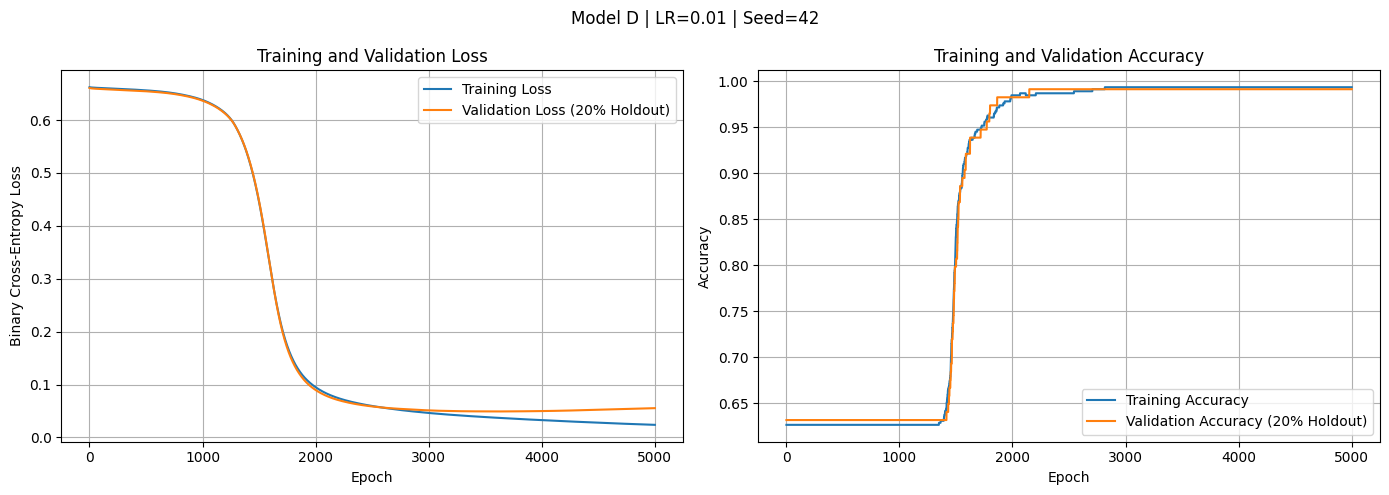

In [168]:

# Plot training and evaluation history

epochs = range(1, len(training_history["train_losses"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LOSS PLOT
axes[0].plot(
    epochs,
    training_history["train_losses"],
    label="Training Loss"
)

axes[0].plot(
    epochs,
    training_history["val_losses"],
    label="Validation Loss (20% Holdout)"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()
axes[0].grid(True)

# ACCURACY PLOT
axes[1].plot(
    epochs,
    training_history["train_accuracies"],
    label="Training Accuracy"
)

axes[1].plot(
    epochs,
    training_history["val_accuracies"],
    label="Validation Accuracy (20% Holdout)"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].legend()
axes[1].grid(True)

fig.suptitle(
    f"Model {best_name} | LR={best_lr} | Seed={final_seed}"
)

plt.tight_layout()

# Save figure for LaTeX report
import os

os.makedirs("figures/problem2", exist_ok=True)

fig.savefig(
    "figures/problem2/problem2a_training_curves.pdf",
    bbox_inches="tight"
)

plt.show()


Model: D
Architecture: [30, 20, 10, 5]
Learning Rate: 0.01
Seed: 42
Training Epochs: 5000
Training Samples: 455
Test Samples: 114

Test Accuracy:  0.9912
Test Precision: 1.0000
Test Recall:    0.9762
Test F1-Score:  0.9880


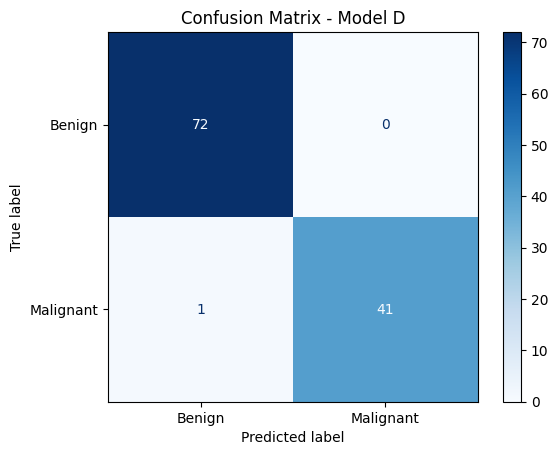

True Negatives:  72
False Positives: 0
False Negatives: 1
True Positives:  41


In [169]:

# FINAL TEST EVALUATION

best_model.eval()

with torch.no_grad():

    # Raw logits
    test_logits = best_model(X_test_tensor)

    # Convert logits to probabilities
    test_probabilities = torch.sigmoid(
        test_logits
    ).cpu().numpy().ravel()

# Convert probabilities to binary predictions
y_pred = (test_probabilities >= 0.5).astype(int)

# True labels
y_true = np.asarray(y_test).ravel()

# Classification metrics
# Positive class: 1 = Malignant
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, pos_label=1, zero_division=0
)
recall = recall_score(
    y_true, y_pred, pos_label=1, zero_division=0
)
f1 = f1_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

# Print model configuration
print(f"Model: {best_name}")
print(f"Architecture: {architectures[best_name]}")
print(f"Learning Rate: {best_lr}")
print(f"Seed: {final_seed}")
print(f"Training Epochs: {final_epochs}")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}\n")

# Print test performance
print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-Score:  {f1:.4f}")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap=plt.cm.Blues, values_format="d")
plt.title(f"Confusion Matrix - Model {best_name}")

# Save figure for LaTeX report
import os

os.makedirs("figures/problem2", exist_ok=True)

disp.figure_.savefig(
    "figures/problem2/problem2a_confusion_matrix.pdf",
    bbox_inches="tight"
)

plt.show()

# Confusion matrix details
print(f"True Negatives:  {cm[0, 0]}")
print(f"False Positives: {cm[0, 1]}")
print(f"False Negatives: {cm[1, 0]}")
print(f"True Positives:  {cm[1, 1]}")


# Problem 2b

**Logistic Regression**

In [170]:

from sklearn.linear_model import LogisticRegression

# Logistic Regression with 80/20 Train-Test Split

# Create model
best_logreg = LogisticRegression(
    C=1.0,
    max_iter=3000,
    random_state=42
)

# Train on 80% of the dataset
best_logreg.fit(X_train_scaled, y_train)

# Display configuration
print("Logistic Regression")
print("Regularization C: 1.0")
print("Maximum Iterations: 3000")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")


Logistic Regression
Regularization C: 1.0
Maximum Iterations: 3000
Training Samples: 455
Test Samples: 114


**Support Vector Machine Classification**

In [171]:

from sklearn.svm import SVC

# Support Vector Machine with 80/20 Train-Test Split

# Create model
best_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

# Train on 80% of the dataset
best_svm.fit(X_train_scaled, y_train)

# Display configuration
print("Support Vector Machine")
print("Kernel: RBF")
print("Regularization C: 1.0")
print("Gamma: scale")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")


Support Vector Machine
Kernel: RBF
Regularization C: 1.0
Gamma: scale
Training Samples: 455
Test Samples: 114


**Final Test Performance Comparison**

In [172]:

# FINAL MODEL COMPARISON

# True test labels
y_true = np.asarray(y_test).ravel()

# Logistic Regression predictions
logreg_pred = best_logreg.predict(X_test_scaled)

# SVM predictions
svm_pred = best_svm.predict(X_test_scaled)

# Neural Network predictions
best_model.eval()

with torch.no_grad():
    nn_logits = best_model(X_test_tensor)
    nn_probabilities = torch.sigmoid(
        nn_logits
    ).cpu().numpy().ravel()

nn_pred = (nn_probabilities >= 0.5).astype(int)


# Function to calculate classification metrics
def evaluate_classifier(name, predictions):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        )
    }


# Compare all three models
comparison_results = [
    evaluate_classifier("Neural Network", nn_pred),
    evaluate_classifier("Logistic Regression", logreg_pred),
    evaluate_classifier("SVM", svm_pred)
]

comparison_df = pd.DataFrame(comparison_results)

# Sort by F1 score and recall
comparison_df = comparison_df.sort_values(
    ["F1", "Recall"],
    ascending=False
).reset_index(drop=True)

display(comparison_df)


# Identify highest F1 and possible ties
best_f1 = comparison_df["F1"].max()

f1_tied = comparison_df[
    np.isclose(comparison_df["F1"], best_f1)
]

best_recall = f1_tied["Recall"].max()

best_models = f1_tied.loc[
    np.isclose(f1_tied["Recall"], best_recall),
    "Model"
].tolist()

print(f"Best Test F1: {best_f1:.4f}")

if len(best_models) == 1:
    print(f"Highest Ranked Model: {best_models[0]}")
else:
    print("Tie between:", ", ".join(best_models))

print(f"\nTest Samples: {len(y_true)}")


,Model,Accuracy,Precision,Recall,F1
0,Neural Network,0.991228,1.000,0.976190,0.987952
1,SVM,0.973684,1.000,0.928571,0.962963
2,Logistic Regression,0.964912,0.975,0.928571,0.951220


Best Test F1: 0.9880
Highest Ranked Model: Neural Network

Test Samples: 114
